In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [2]:
rs = 100 # Globalizando random state

In [3]:
dadosNacional = pd.read_parquet("../outputs/dadosFinal.parquet")
dadosNorte = pd.read_parquet("../outputs/dadosNorte.parquet")
dadosNordeste = pd.read_parquet("../outputs/dadosNordeste.parquet")
dadosCentroOeste = pd.read_parquet("../outputs/dadosCentroOeste.parquet")
dadosSudeste = pd.read_parquet("../outputs/dadosSudeste.parquet")
dadosSul = pd.read_parquet("../outputs/dadosSul.parquet")

In [4]:
bancos = {
    "Nacional": dadosNacional,
    "Norte": dadosNorte,
    "Nordeste": dadosNordeste,
    "Centro-Oeste": dadosCentroOeste,
    "Sudeste": dadosSudeste,
    "Sul": dadosSul
}

In [5]:
dadosVarBin = {}

for regiao, dados in bancos.items():

    dados["atraso60Binario"] = dados["atraso60"].map({
        "Pontual": 0,
        "Atraso": 1
    })

    y = dados["atraso60Binario"]

    X = dados.drop(columns=[
        "atraso60",
        "atraso60Binario"
    ])

    dadosVarBin[regiao] = {
        "dados": dados,
        "X": X,
        "y": y
    }

In [6]:
for regiao, dados in dadosVarBin.items():
    X = dados["X"]
    
    categoricas = X.select_dtypes(include=['object', 'category']).columns
    numericas = X.select_dtypes(exclude=['object', 'category']).columns
    
    dados["categoricas"] = categoricas
    dados["numericas"] = numericas

In [7]:
for regiao, dados in dadosVarBin.items():
    X = dados["X"]
    y = dados["y"]
    categoricas = dados["categoricas"]
    numericas = dados["numericas"]

    pipeCategoricas = Pipeline([
        ('onehot', OneHotEncoder(handle_unknown='ignore')) # Transforma as colunas em números para a RF conseguir interpretar. handle unknown ignora colunas desconhecidas
    ])

    pipeNumericas = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)) # Preenche NaN pela mediana antes de entrar na RF
    ])

    preprocessador = ColumnTransformer([
        ('cat', pipeCategoricas, categoricas),
        ('num', pipeNumericas, numericas)
    ])

    arvoreEstocastica = Pipeline([
        ('preprocessador', preprocessador),
        ('rf', RandomForestClassifier(
            n_jobs=-1,
            random_state=rs
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=rs, stratify=y
    )

    dados["arvoreEstocastica"] = arvoreEstocastica
    dados["X_train"] = X_train
    dados["X_test"] = X_test
    dados["y_train"] = y_train
    dados["y_test"] = y_test

In [8]:
for regiao, dados in dadosVarBin.items():
    X_train = dados["X_train"]
    y_train = dados["y_train"]
    X_test = dados["X_test"]
    y_test = dados["y_test"]
    arvoreEstocastica = dados["arvoreEstocastica"]

    arvoreEstocastica.fit(X_train, y_train) # Treinando os modelos
    pred = arvoreEstocastica.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, pred)
    print(f"{regiao} — AUC: {auc}")

    dados["auc"] = auc

Nacional — AUC: 0.7481931238263807
Norte — AUC: 0.7587801167208539
Nordeste — AUC: 0.7481998428257134
Centro-Oeste — AUC: 0.7905756844773507
Sudeste — AUC: 0.7317222256312622
Sul — AUC: 0.7836528877028925


In [9]:
from joblib import parallel_backend

for regiao, dados in dadosVarBin.items():
    if "resultadoPermutacao" in dados:
        continue

    X_test = dados["X_test"]
    y_test = dados["y_test"]
    arvoreEstocastica = dados["arvoreEstocastica"]

    amostra = X_test.sample(10000, random_state=rs).index
    with parallel_backend("threading"):
        resultadoPermutacao = permutation_importance( # Importância por permutação
            arvoreEstocastica,
            X_test.loc[amostra],
            y_test.loc[amostra],
            n_repeats=3,
            random_state=rs,
            n_jobs=-1
        )
    dados["resultadoPermutacao"] = resultadoPermutacao
    print(f"{regiao} — permutação concluída")

Nacional — permutação concluída
Norte — permutação concluída
Nordeste — permutação concluída
Centro-Oeste — permutação concluída
Sudeste — permutação concluída
Sul — permutação concluída


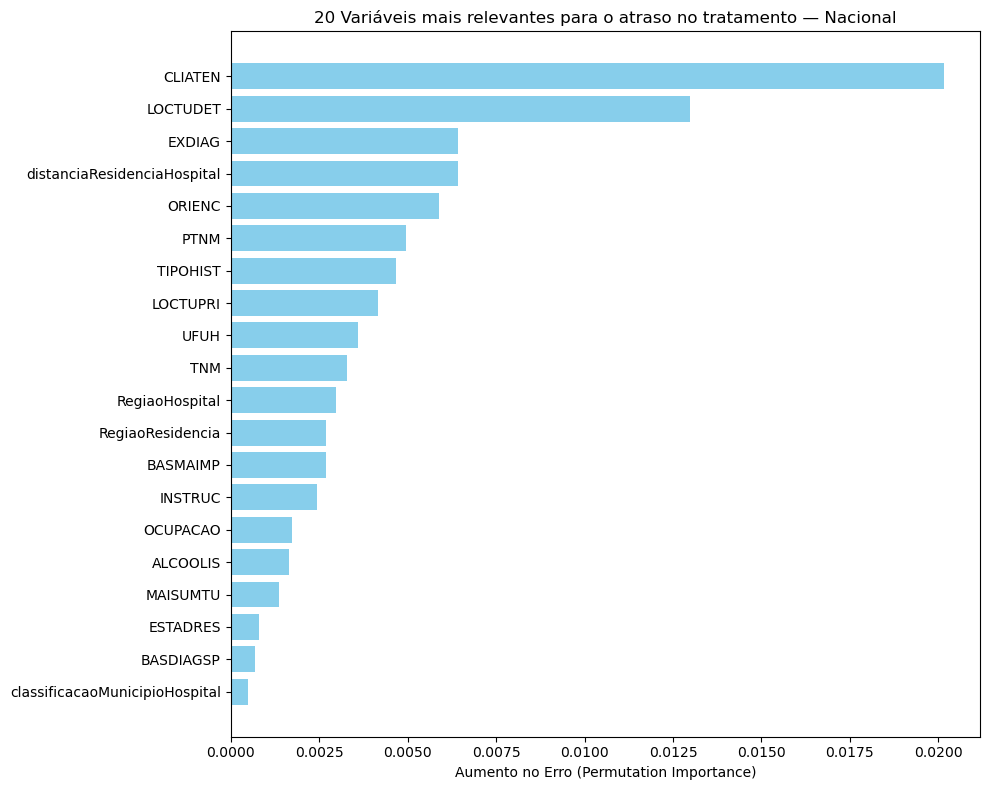

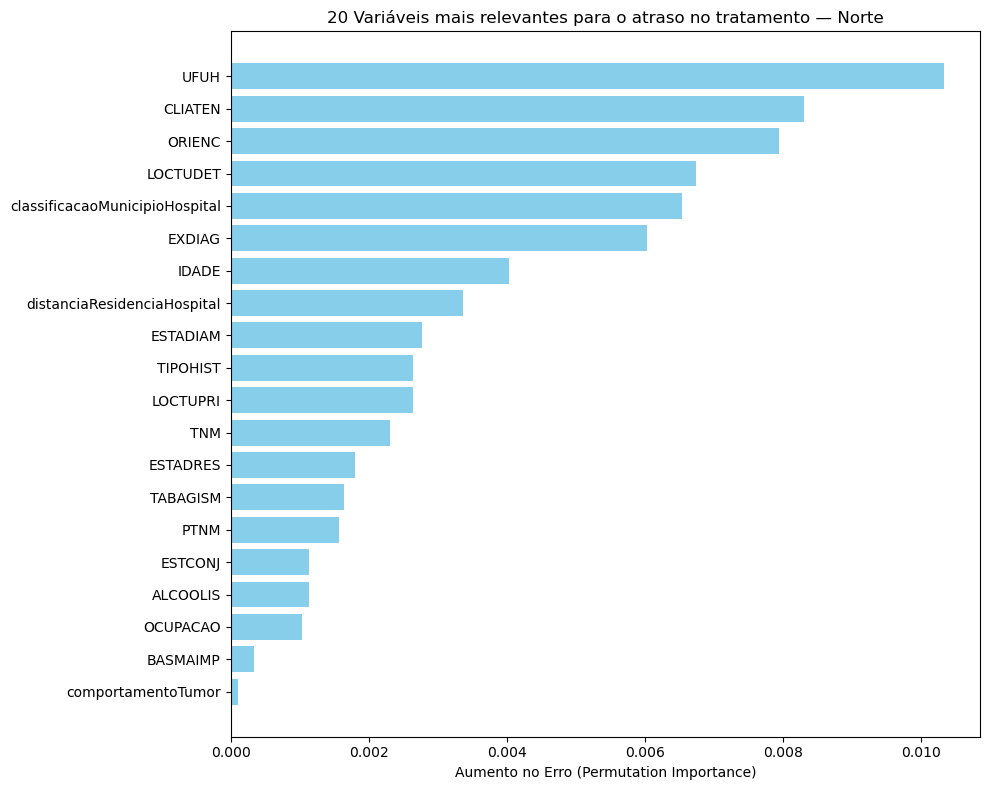

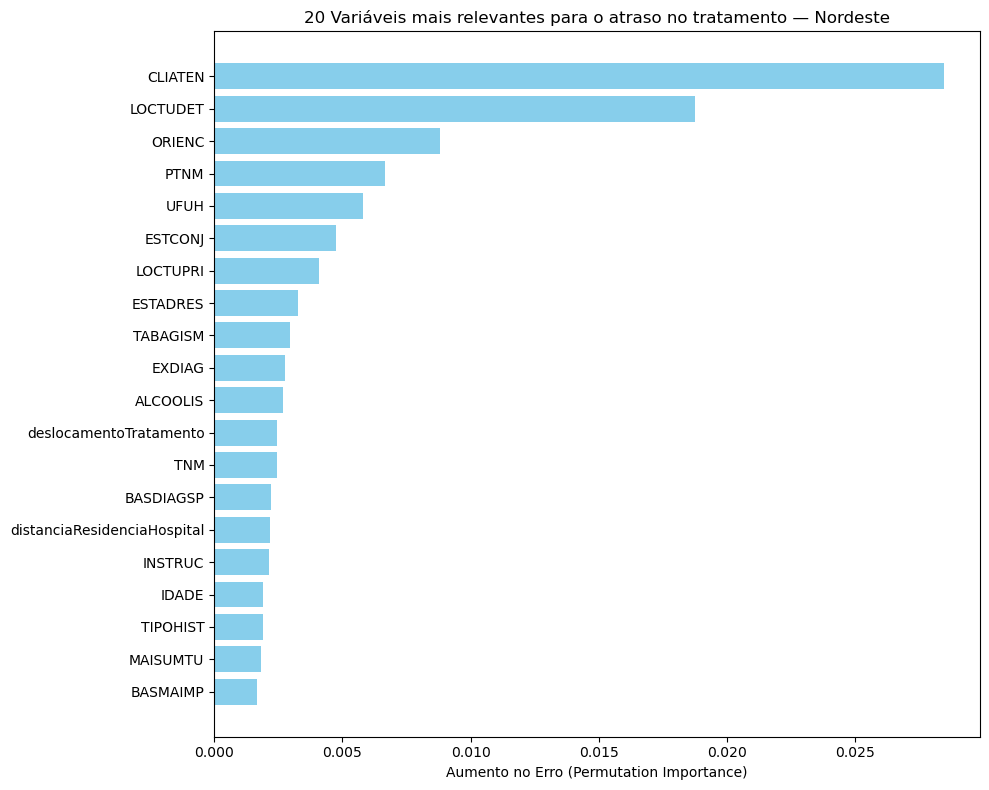

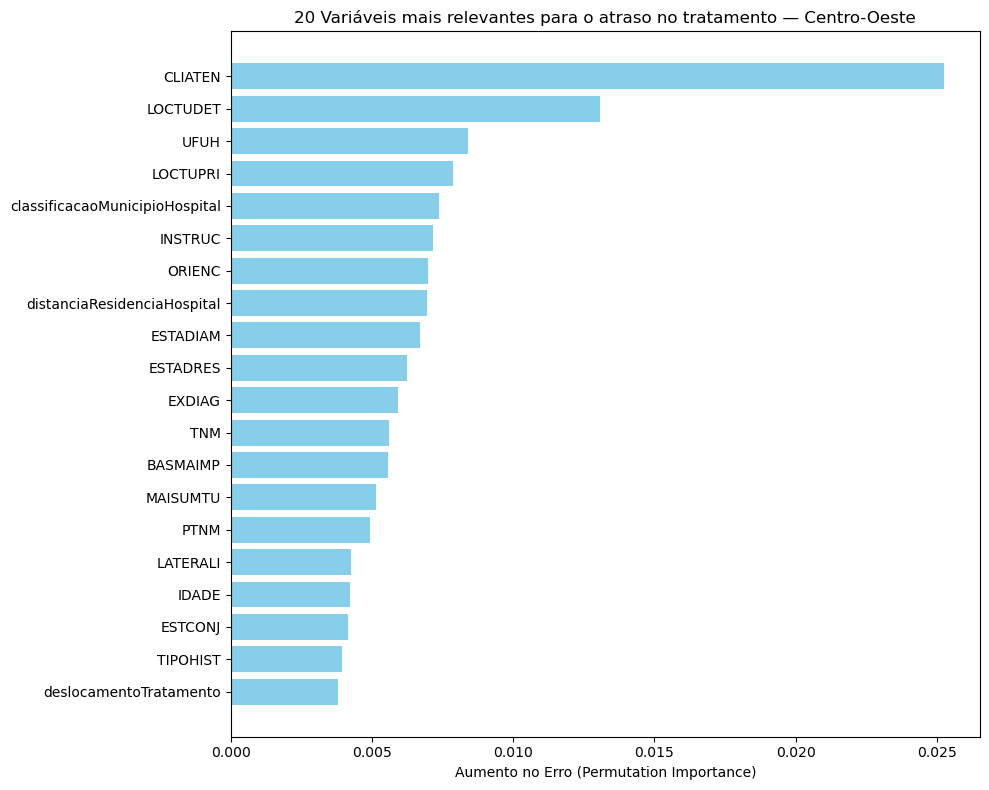

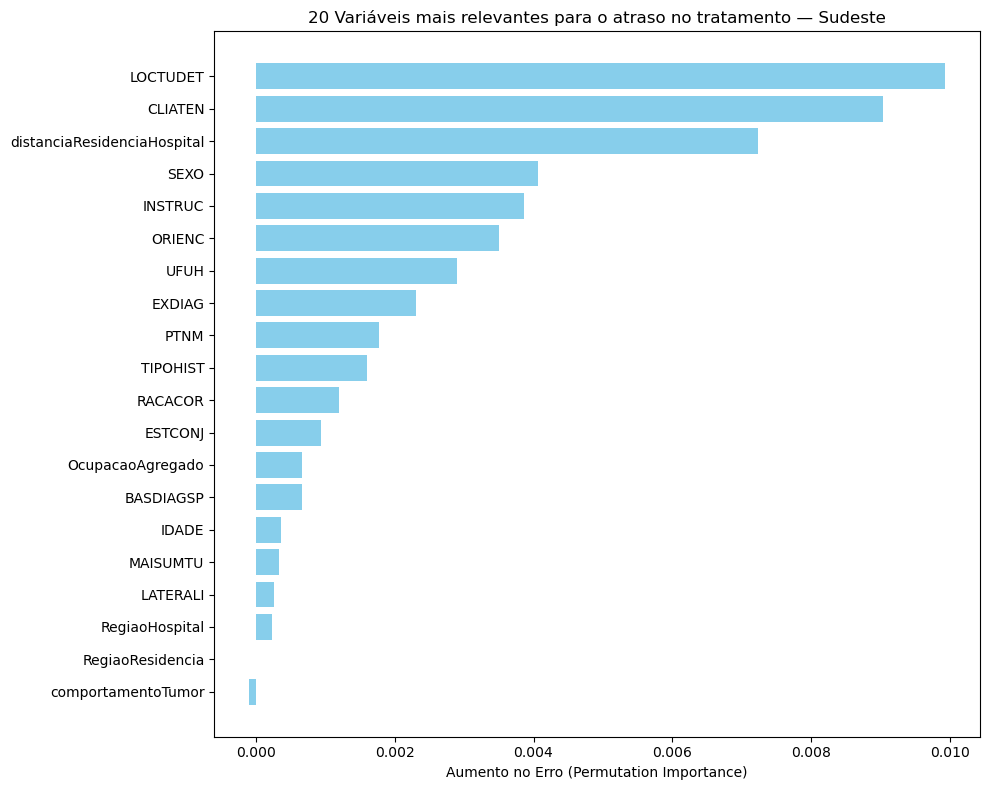

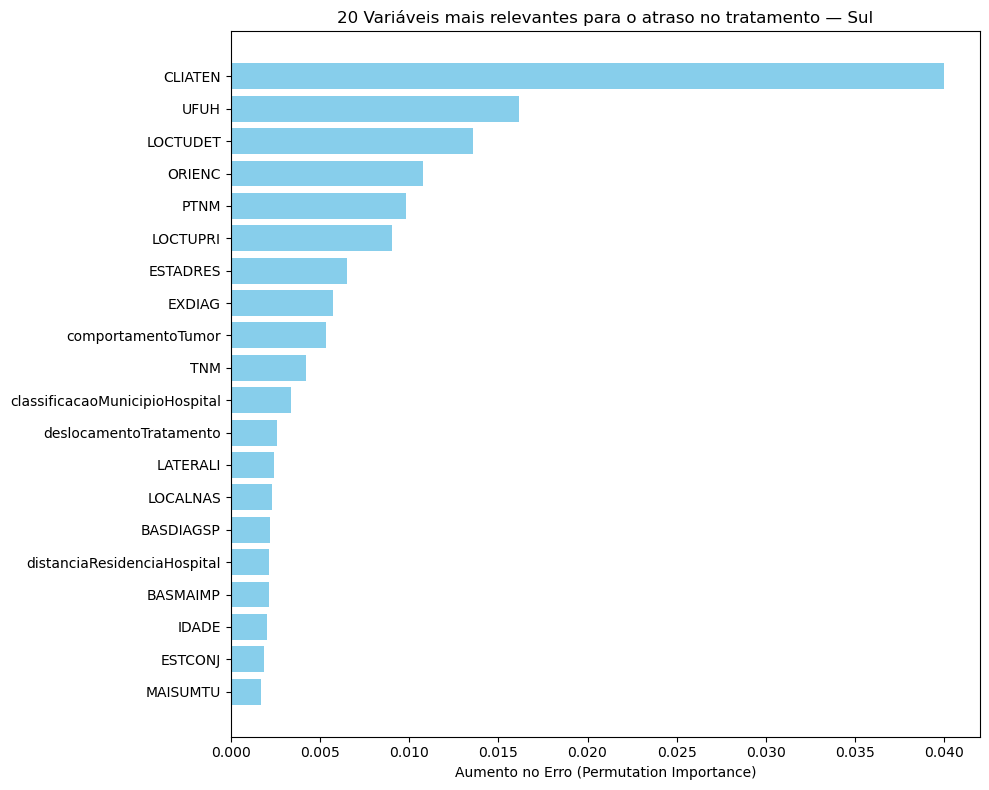

In [10]:
for regiao, dados in dadosVarBin.items():
    X_test = dados["X_test"]
    auc = dados["auc"]
    arvoreEstocastica = dados["arvoreEstocastica"]
    resultadoPermutacao = dados["resultadoPermutacao"]
    
    nomeVariavel = (  # Nomes das colunas depois do OneHotEncoder
        arvoreEstocastica.named_steps['preprocessador']
        .get_feature_names_out()
    )

    featureImportance = pd.DataFrame({ # Cria o DataFrame com os nomes e valores de importância associados
        "variavel": X_test.columns,
        "importancia": resultadoPermutacao.importances_mean
    })
    
    featureImportance["nome"] = ( # Limpa os nomes das variáveis
        featureImportance["variavel"]
        .str.replace("cat__", "", regex=False)
        .str.replace("num__", "", regex=False)
    )

    fiTopo = featureImportance.sort_values(by="importancia", ascending=False).head(20)
    fiTopo = fiTopo.sort_values(by="importancia", ascending=True)

    plt.figure(figsize=(10, 8))
    plt.barh(fiTopo["nome"], fiTopo["importancia"], color='skyblue')
    plt.xlabel("Aumento no Erro (Permutation Importance)")
    plt.title(f"20 Variáveis mais relevantes para o atraso no tratamento — {regiao}")
    plt.tight_layout()
    plt.show()

    # Guarda tudo dentro do próprio dicionário da região
    dados["modelo"] = arvoreEstocastica
    dados["auc"] = auc
    dados["featureImportance"] = featureImportance
    dados["fiTopo"] = fiTopo